# 🫀 CodeAlpha — Task 4: Disease Prediction from Medical Data

**Objective**: Predict the presence of heart disease from medical data.

**Dataset**: [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease) — Kaggle version (920 patients from 4 hospitals: Cleveland, Hungary, Switzerland, Long Beach).

**Author**: Sawadogo Noé — Machine Learning Intern at [CodeAlpha](https://www.codealpha.tech)

---

## 1. Importing libraries

In [16]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve
)

# Global configuration
RANDOM_STATE = 42
IMAGES_DIR = "images"
os.makedirs(IMAGES_DIR, exist_ok=True)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data loading and exploration

The dataset contains 14 medical attributes per patient. The target variable `num` ranges from 0 to 4:
- `0`: no disease
- `1-4`: increasing severity of heart disease

For this project, we use **binary classification** (0 = healthy, 1 = diseased), which is more suitable for clinical screening.

In [17]:
df = pd.read_csv("data/heart_disease_uci.csv")

print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
print("Columns:")
for col in df.columns:
    print(f"  - {col}")

df.head()

Shape: 920 rows x 16 columns

Columns:
  - id
  - age
  - sex
  - dataset
  - cp
  - trestbps
  - chol
  - fbs
  - restecg
  - thalch
  - exang
  - oldpeak
  - slope
  - ca
  - thal
  - num


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [18]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print("Missing values per column:")
print(missing if len(missing) > 0 else "No missing values.")

print("\nDistribution of variable 'num':")
print(df["num"].value_counts().sort_index())

Missing values per column:
ca          611
thal        486
slope       309
fbs          90
oldpeak      62
trestbps     59
exang        55
thalch       55
chol         30
restecg       2
dtype: int64

Distribution of variable 'num':
num
0    411
1    265
2    109
3    107
4     28
Name: count, dtype: int64


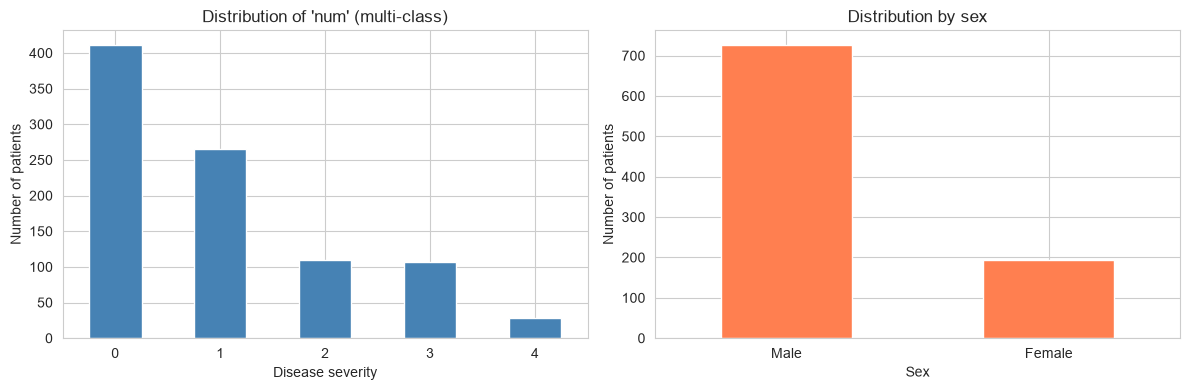

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["num"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of 'num' (multi-class)")
axes[0].set_xlabel("Disease severity")
axes[0].set_ylabel("Number of patients")
axes[0].tick_params(axis='x', rotation=0)

df["sex"].value_counts().plot(kind="bar", ax=axes[1], color="coral")
axes[1].set_title("Distribution by sex")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Number of patients")
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

## 3. Data preprocessing

Steps applied:
1. **Drop** non-predictive columns (`id`, `dataset`).
2. **Binarize** the target `num` → `target` (0 = healthy, 1 = diseased).
3. **Impute** missing values (median for numeric, mode for categorical).

> **Observation**: `ca` and `thal` have significant missingness (~66% and ~53%) because they are only recorded in some hospitals (Cleveland, Long Beach). We keep them and impute rather than dropping, to preserve potential signal.

4. **One-Hot Encoding** of categorical features (`cp`, `restecg`, `slope`, `thal`, `sex`).
5. **Standardize** features with `StandardScaler` (essential for SVM and Logistic Regression).

In [20]:
# 1. Drop non-predictive columns
for col in ["id", "dataset", "origin"]:
    if col in df.columns:
        df = df.drop(col, axis=1)

# 2. Binarize the target
df["target"] = (df["num"] > 0).astype(int)
df = df.drop("num", axis=1)

print("Binary target distribution:")
print(df["target"].value_counts())
print(f"Diseased proportion: {df['target'].mean():.2%}")

Binary target distribution:
target
1    509
0    411
Name: count, dtype: int64
Diseased proportion: 55.33%


In [21]:
# 3. Impute missing values
for col in df.columns:
    if col == "target":
        continue
    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            df[col] = df[col].fillna(df[col].mode()[0])

# Convert boolean columns to int
for col in df.select_dtypes(include=["bool"]).columns:
    df[col] = df[col].astype(int)

# 4. One-Hot Encoding of categorical features
cat_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()
print(f"Categorical columns encoded: {cat_cols}")
df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)

print(f"\nShape after preprocessing: {df.shape}")
print(f"Remaining missing values: {df.isnull().sum().sum()}")
print(f"\nFinal columns:\n{list(df.columns)}")

Categorical columns encoded: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'thal']

Shape after preprocessing: (920, 19)
Remaining missing values: 0

Final columns:
['age', 'trestbps', 'chol', 'thalch', 'oldpeak', 'ca', 'target', 'sex_Male', 'cp_atypical angina', 'cp_non-anginal', 'cp_typical angina', 'fbs_True', 'restecg_normal', 'restecg_st-t abnormality', 'exang_True', 'slope_flat', 'slope_upsloping', 'thal_normal', 'thal_reversable defect']


## 4. Train/test split and scaling

- **80%** of data for training, **20%** for testing.
- **Stratified split** on `target` to preserve the proportion of diseased patients in both sets.
- **StandardScaler** fitted only on training data to avoid **data leakage**.

In [22]:
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")

Training set: (736, 18)
Test set:     (184, 18)


## 5. Training and comparing 4 models

As required by the task, we compare:
- **Logistic Regression** (linear baseline)
- **SVM (RBF kernel)** (non-linear maximum margin)
- **Random Forest** (tree ensemble)
- **XGBoost** (gradient boosting)

Metrics: Accuracy, Precision, Recall, F1-Score, ROC-AUC.

In [25]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "SVM (RBF)": CalibratedClassifierCV(
        SVC(random_state=RANDOM_STATE), ensemble=False, cv=5
    ),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=4,
        eval_metric="logloss", random_state=RANDOM_STATE
    ),
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\n{'=' * 55}\n{name}\n{'=' * 55}")
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model

    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba),
    })

    print(classification_report(y_test, y_pred, target_names=["Healthy", "Diseased"]))


Logistic Regression
              precision    recall  f1-score   support

     Healthy       0.84      0.79      0.82        82
    Diseased       0.84      0.88      0.86       102

    accuracy                           0.84       184
   macro avg       0.84      0.84      0.84       184
weighted avg       0.84      0.84      0.84       184


SVM (RBF)
              precision    recall  f1-score   support

     Healthy       0.89      0.78      0.83        82
    Diseased       0.84      0.92      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.85      0.85       184
weighted avg       0.86      0.86      0.86       184


Random Forest
              precision    recall  f1-score   support

     Healthy       0.88      0.79      0.83        82
    Diseased       0.85      0.91      0.88       102

    accuracy                           0.86       184
   macro avg       0.86      0.85      0.86       184
weighted avg       0.86    

In [26]:
results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
results_df.to_csv("results.csv", index=False)

print("Model comparison:")
results_df.round(4)

Model comparison:


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
1,SVM (RBF),0.8587,0.8393,0.9216,0.8785,0.9192
2,Random Forest,0.8587,0.8455,0.9118,0.8774,0.9171
3,XGBoost,0.8315,0.8447,0.8529,0.8488,0.9103
0,Logistic Regression,0.8424,0.8411,0.8824,0.8612,0.9032


## 6. Performance visualization

### 6.1 Metric comparison by model

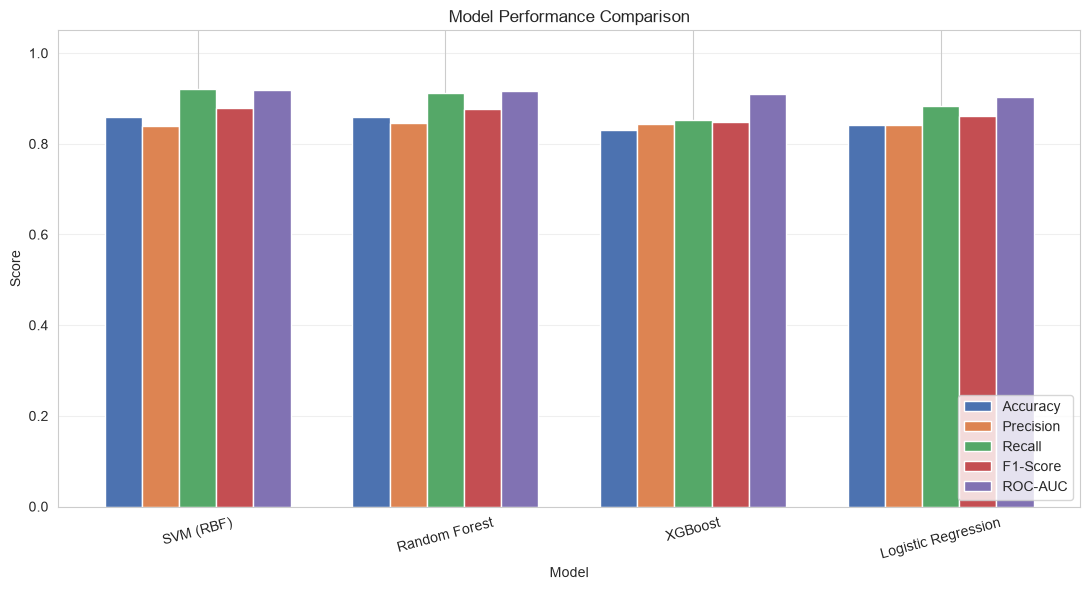

In [27]:
fig, ax = plt.subplots(figsize=(11, 6))
x = np.arange(len(results_df))
width = 0.15
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
colors = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3"]

for i, (metric, color) in enumerate(zip(metrics, colors)):
    ax.bar(x + i * width, results_df[metric], width, label=metric, color=color)

ax.set_xlabel("Model")
ax.set_ylabel("Score")
ax.set_title("Model Performance Comparison")
ax.set_xticks(x + width * 2)
ax.set_xticklabels(results_df["Model"], rotation=15)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.2 ROC curves

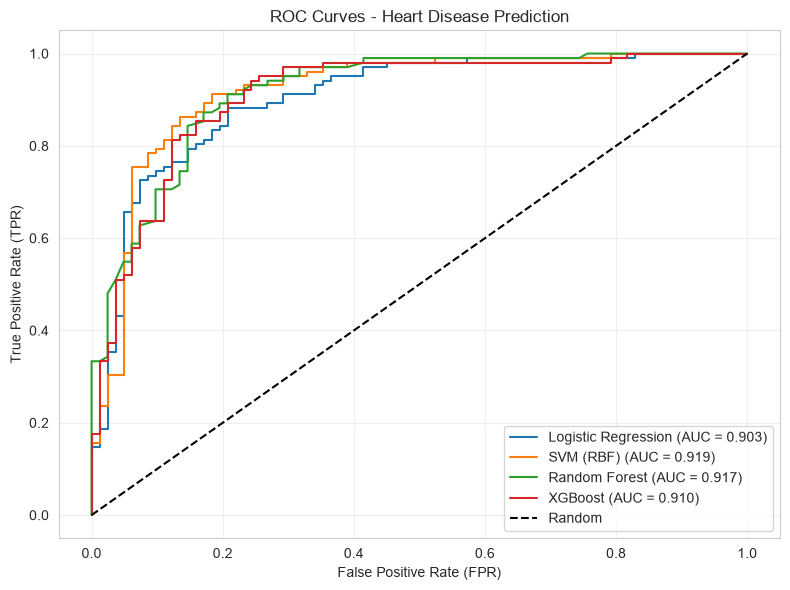

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], "k--", label="Random")
ax.set_xlabel("False Positive Rate (FPR)")
ax.set_ylabel("True Positive Rate (TPR)")
ax.set_title("ROC Curves - Heart Disease Prediction")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.3 Confusion matrices

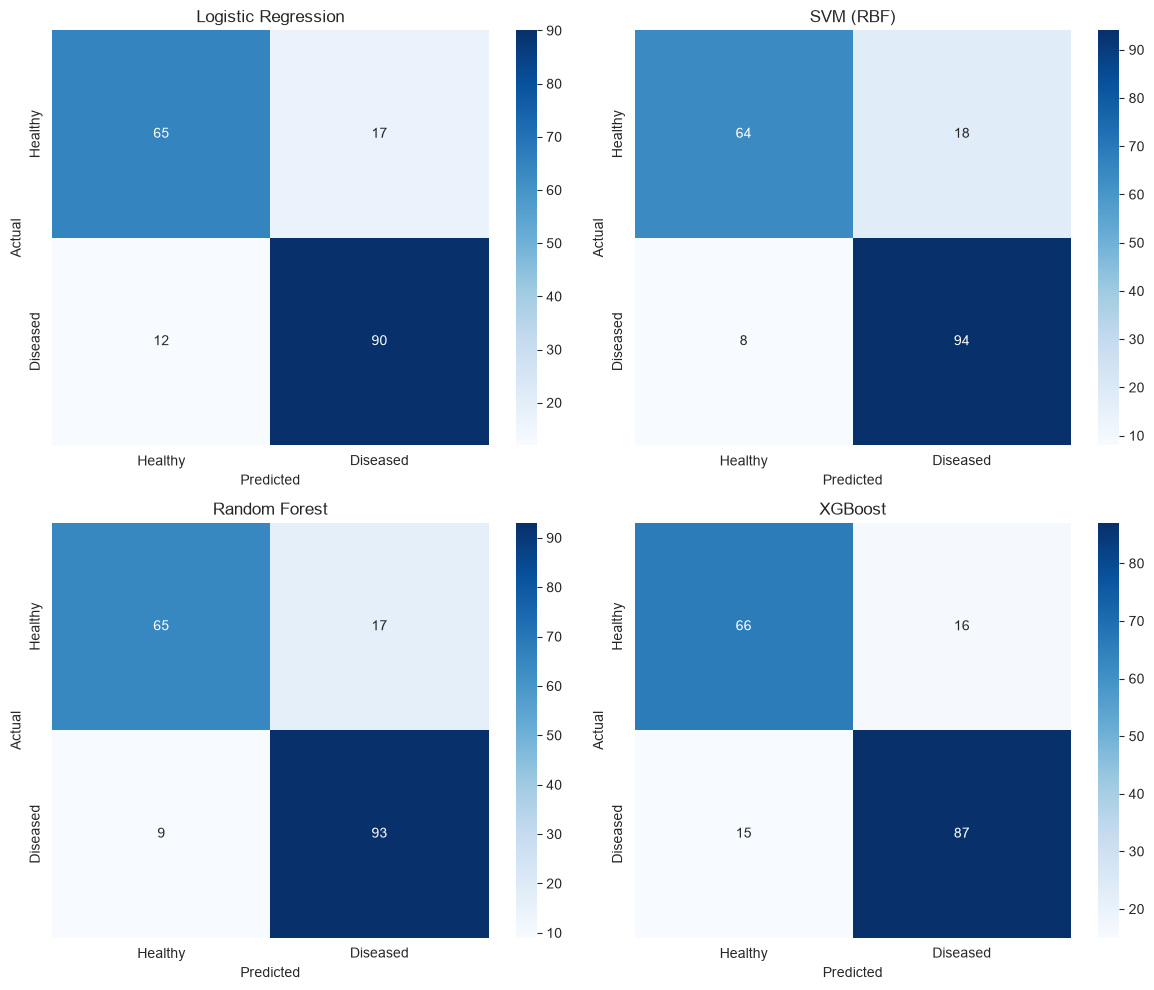

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (name, model) in zip(axes.ravel(), trained_models.items()):
    y_pred = model.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["Healthy", "Diseased"],
                yticklabels=["Healthy", "Diseased"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

### 6.4 Feature importance (Random Forest)

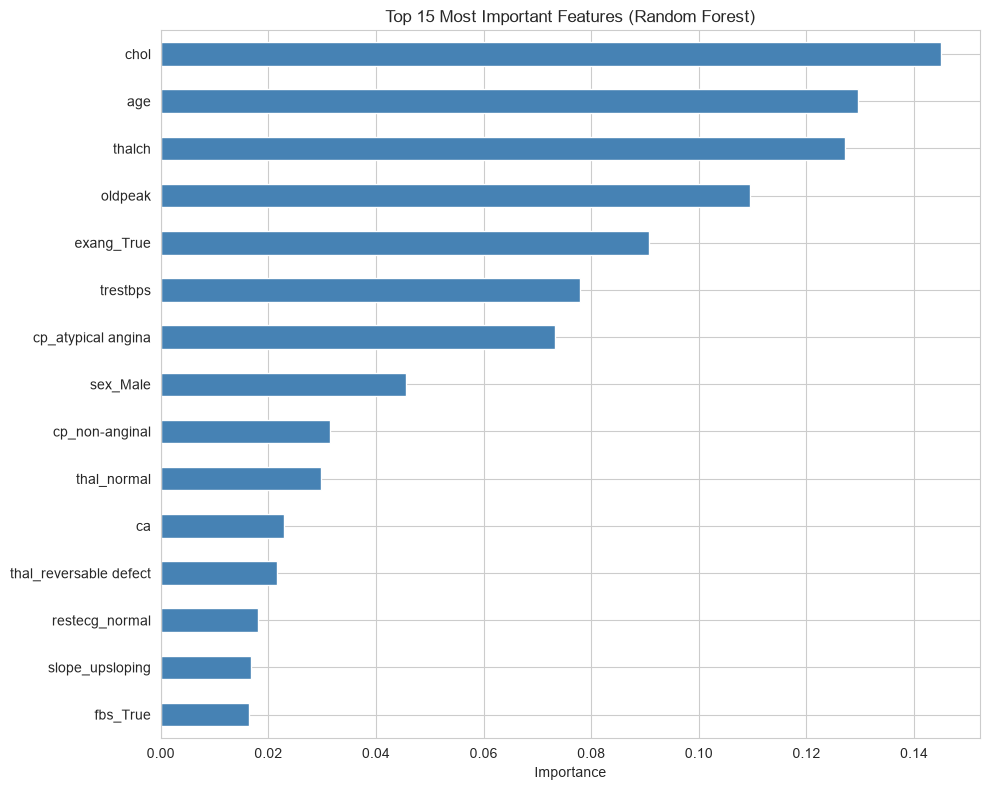

Top 5 most important features:
chol          0.1450
age           0.1296
thalch        0.1272
oldpeak       0.1096
exang_True    0.0907
dtype: float64


In [30]:
rf = trained_models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 8))
importances.head(15).plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Importance")
ax.set_title("Top 15 Most Important Features (Random Forest)")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(f"{IMAGES_DIR}/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

print("Top 5 most important features:")
print(importances.head(5).round(4))

In [31]:
import joblib

# Save the best model, scaler, and feature names for the Streamlit app
joblib.dump(trained_models["SVM (RBF)"], "model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(list(X.columns), "features.pkl")

print("Model, scaler and features saved successfully.")

Model, scaler and features saved successfully.


## 7. Conclusion

All four models achieved high performance (ROC-AUC > 0.90), confirming the predictive power of the medical features in the UCI Heart Disease dataset.

### Key results

| Model | Accuracy | F1-Score | ROC-AUC |
|---|---|---|---|
| **SVM (RBF)** | **0.8587** | **0.8785** | **0.9192** |
| **Random Forest** | **0.8587** | 0.8774 | 0.9171 |
| XGBoost | 0.8315 | 0.8488 | 0.9103 |
| Logistic Regression | 0.8424 | 0.8612 | 0.9032 |

**SVM (RBF)** and **Random Forest** are tied on accuracy (85.87%), with SVM achieving the highest ROC-AUC (0.9192) — making it the best overall model for this task.

### Key insights

- **Feature importance** (Random Forest) identified `chol` (cholesterol), `age`, `thalch` (max heart rate), `oldpeak` (ST depression) and `exang` (exercise-induced angina) as the top 5 predictors — all clinically consistent with cardiovascular risk factors.
- **Handling missing data** in `ca` (~66% missing) and `thal` (~53% missing) through median/mode imputation preserved the signal without discarding patients.
- **One-Hot Encoding** and **StandardScaler** were crucial for linear models (Logistic Regression, SVM) to compete with tree-based ensembles.

### Limitations and future work

- **Multi-class classification** (0–4 severity) could provide finer-grained diagnosis.
- **K-fold cross-validation** would give a more robust performance estimate.
- **Hyperparameter tuning** (GridSearchCV / Optuna) could further improve results.
- **Deployment** as a REST API (FastAPI / Flask) for real-world clinical use.

---

*Project completed as part of the Machine Learning Internship at [CodeAlpha](https://www.codealpha.tech).*